In [42]:
import numpy as np
import matplotlib
%matplotlib inline  
# matplotlib.use("TkAgg")    # or "Qt5Agg" depending on what you have installed
import matplotlib.pyplot as plt
from matplotlib import rcParams
from astropy import units as u
from scipy.stats import norm
import scipy.interpolate as si

AU_cm = (1 * u.AU).to(u.cm).value

In [20]:
params = {
   'axes.labelsize': 20,
   'font.size': 20,
   'legend.fontsize': 10,
   'xtick.labelsize': 20,
   'ytick.labelsize': 15,
   #'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [21]:
# Re-run sampling without scipy.cumtrapz dependency, using a simple trapezoidal cumulative sum.
import numpy as np
import matplotlib.pyplot as plt

def sample_x_times_lognormal(mode=0.78, sigma=0.25, bounds=(0.5, 1.0), n_grid=5000, n_samples=150, save_path="samples_a_gpt.txt"):
    x_min, x_max = bounds
    x = np.linspace(x_min, x_max, n_grid)
    
    mu = np.log(mode) + sigma**2  # set mode
    
    with np.errstate(divide='ignore'):
        lognormal_pdf = (1.0 / (x * sigma * np.sqrt(2*np.pi))) * np.exp(- (np.log(x) - mu)**2 / (2*sigma**2))
    
    pdf = x * lognormal_pdf
    
    integral = np.trapz(pdf, x)
    if integral <= 0 or not np.isfinite(integral):
        raise RuntimeError("PDF integral not positive/finite; check parameters.")
    pdf_norm = pdf / integral
    
    # cumulative trapezoid (manual)
    dx = x[1] - x[0]
    # compute trapezoid areas between consecutive points
    trap_areas = 0.5 * (pdf_norm[:-1] + pdf_norm[1:]) * dx
    cdf = np.concatenate(([0.0], np.cumsum(trap_areas)))
    cdf = np.clip(cdf, 0.0, 1.0)
    cdf /= cdf[-1]
    
    u = np.random.rand(n_samples)
    samples = np.interp(u, cdf, x)
    np.savetxt(save_path, samples, fmt="%.8e")
    return samples, x, pdf_norm, cdf, save_path, lognormal_pdf

a_samples_ueda, x_grid, pdf_norm, cdf, save_path, lognormal_pdf = sample_x_times_lognormal(mode=0.78, sigma=0.25, bounds=(0.5, 1.0), n_grid=5000, n_samples=1000)

print(f"Generated {a_samples_ueda.size} samples.")
print(f"Sample mean = {a_samples_ueda.mean():.6f}, median = {np.median(a_samples_ueda):.6f}, std = {a_samples_ueda.std():.6f}")
print(f"Saved samples to: {save_path}")

a_samples_ueda[:10]



Generated 1000 samples.
Sample mean = 0.792342, median = 0.796038, std = 0.120733
Saved samples to: samples_a_gpt.txt


/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_39975/3651336195.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(pdf, x)


array([0.75239308, 0.86147166, 0.82719382, 0.89606586, 0.83539891,
       0.7992976 , 0.94928439, 0.96779047, 0.96996509, 0.889283  ])

In [22]:
def compute_surface_density(semi_major_axes, m_g, bins=None):
    """
    Estimate Sigma(a) from sampled bodies of equal mass m_g (grams).
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 25)
    counts, edges = np.histogram(semi_major_axes, bins=bins)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2) * AU_cm**2)
    sigma = counts * m_g / areas
    centers = 0.5 * (r1 + r2)
    return centers, sigma

n_samples = len(a_samples_ueda)
m_pl_ueda = (2.2 * u.M_earth.to(u.g))/n_samples
centers, sigmas = compute_surface_density(a_samples_ueda, m_pl_ueda, bins = np.linspace(0.3, 1.2, 8))

In [ ]:
#Read from plot in the paper, use the grid to extrapolate
import pandas as pd

ueda_from_paper_df = pd.read_csv('ueda_sigma_grid.csv')


ueda_from_paper = si.interp1d(ueda_from_paper_df['r'], ueda_from_paper_df['sigma'])

In [ ]:
import pandas as pd
import numpy as np
import scipy.interpolate as si

# Load digitized data
ueda_from_paper_df = pd.read_csv("ueda_sigma_grid.csv")

r = ueda_from_paper_df["r"].values
sigma = ueda_from_paper_df["sigma"].values

# Interpolator in log–log space
log_interp = si.interp1d(
    np.log(r),
    np.log(sigma),
    kind="linear",   # straight lines in log–log space
    fill_value="extrapolate"  # allow extrapolation beyond data
)

def ueda_from_paper(r_new):
    """Extrapolated sigma(r) from paper plot (log–log interpolation)."""
    return np.exp(log_interp(np.log(r_new)))

# Example: finer grid
r_fine = np.logspace(np.log10(r.min()), np.log10(r.max()), 100)
sigma_fine = ueda_from_paper(r_fine)


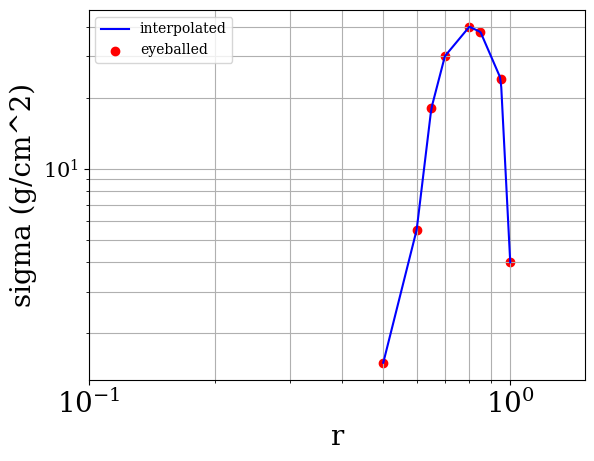

In [60]:
plt.plot(r_fine, sigma_fine, color = 'blue', label = 'interpolated')
plt.scatter(ueda_from_paper_df['r'], ueda_from_paper_df['sigma'], color = 'red', label = 'eyeballed')


plt.grid('True', 'both')

plt.xlim(0.1, 1.5)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("r")
plt.ylabel("sigma (g/cm^2)")
plt.legend()
plt.show()
plt.show()

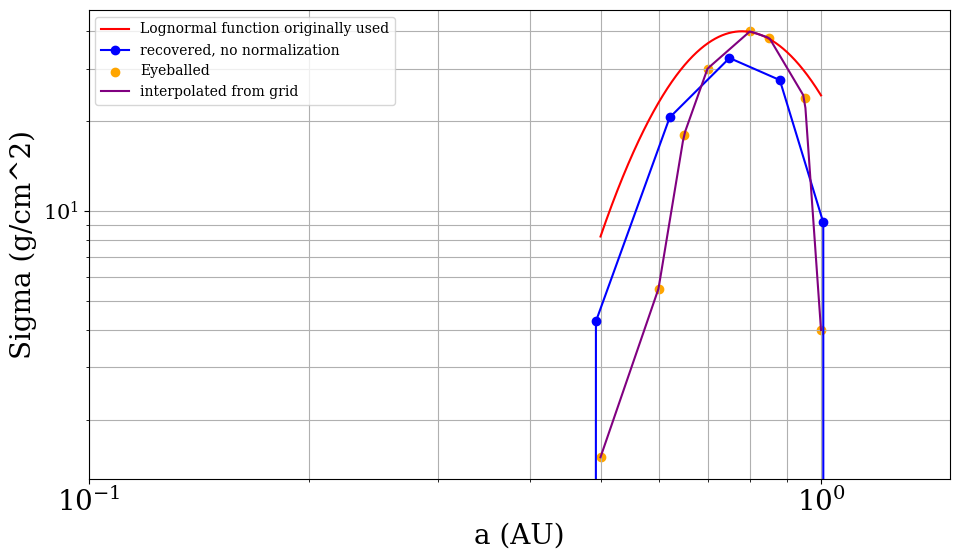

In [57]:
plt.figure(figsize=(10,6))

plt.plot(np.linspace(0.5, 1, 5000), lognormal_pdf * 40/max(lognormal_pdf), label = 'Lognormal function originally used', color = 'red')
plt.plot(centers, sigmas, label='recovered, no normalization', marker = 'o', color = 'blue')
plt.scatter(ueda_from_paper_df['r'], ueda_from_paper_df['sigma'], label = 'Eyeballed', marker='o', color = 'orange')
plt.plot(r_fine, sigma_fine, color = 'purple', label = 'interpolated from grid')
#plt.scatter(centers, sigmas_norm, label = 'recovered, normalized')

plt.xlim(0.1, 1.5)
xticks = np.arange(0.1, 1.6, 0.1)
plt.xticks(xticks)
plt.grid('True', 'both')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('a (AU)')
plt.ylabel('Sigma (g/cm^2)')
plt.tight_layout()
plt.legend()
plt.show()


# UEDA V4

In [26]:
ueda_v4_semis = np.loadtxt("ueda2021_v4.txt")
centers_v4, sigmas_v4 = compute_surface_density(ueda_v4_semis, m_pl_ueda, bins = np.linspace(0.5, 1, 10))

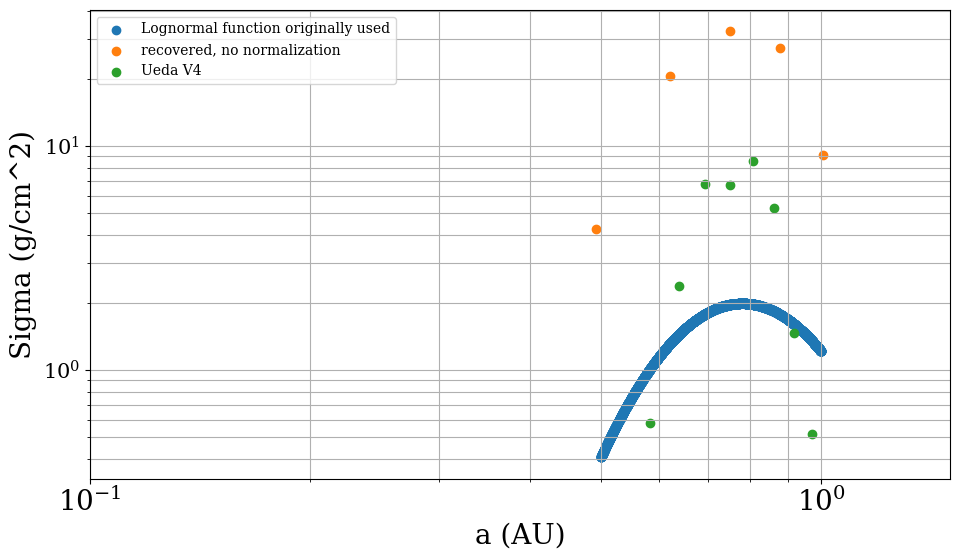

In [27]:
plt.figure(figsize=(10,6))

plt.scatter(np.linspace(0.5, 1, 5000), lognormal_pdf, label = 'Lognormal function originally used')
plt.scatter(centers, sigmas, label='recovered, no normalization')
plt.scatter(centers_v4, sigmas_v4, label = 'Ueda V4')
#plt.scatter(centers, sigmas_norm, label = 'recovered, normalized')

plt.xlim(0.1, 1.5)
xticks = np.arange(0.1, 1.6, 0.1)
plt.xticks(xticks)
plt.grid('True', 'both')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('a (AU)')
plt.ylabel('Sigma (g/cm^2)')
plt.tight_layout()
plt.legend()
plt.show()